# Evaluation: all models on the same test period

This notebook compares every model on the same held-out test period (1 July 2012 to 31 December 2012). It reads the predictions saved by `03-models.ipynb` (`results/preds_baseline.csv` and `results/preds_models.csv`), so run notebook 03 first.

Contents: 4.1 metrics table, 4.2 residual plots, 4.3 errors in peak hours, 4.4 RMSE or R², 4.5 ridge coefficients, 4.6 limitations, 4.7 check of the preprocessing choice.

In [1]:
import sys
sys.path.append('../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from data import load_hour_data, chronological_split, get_xy
from preprocessing import build_preprocessor

# Predictions saved by 03-models.ipynb
base = pd.read_csv('../results/preds_baseline.csv', parse_dates=['dteday'])
models_df = pd.read_csv('../results/preds_models.csv', parse_dates=['dteday'])

# Make sure both files describe exactly the same test rows
assert (base[['dteday', 'hr']].values == models_df[['dteday', 'hr']].values).all()
assert (base['y_true'].values == models_df['y_true'].values).all()

preds = models_df.merge(base[['dteday', 'hr', 'baseline', 'persistence']], on=['dteday', 'hr'])
model_names = ['baseline', 'persistence', 'linear', 'ridge', 'lasso', 'forest']

print('Test rows:', len(preds))
print('Test period:', preds['dteday'].min().date(), 'to', preds['dteday'].max().date())
preds.head()

Test rows: 4376
Test period: 2012-07-01 to 2012-12-31


,dteday,hr,y_true,linear,ridge,lasso,forest,baseline,persistence
0,2012-07-01,0,149,213.703747,213.717003,213.710439,141.4550,218.190681,163.0
1,2012-07-01,1,93,184.322664,184.335555,184.326668,109.8725,219.785255,127.0
2,2012-07-01,2,90,167.914099,167.972862,167.920147,76.7550,221.379829,114.0
3,2012-07-01,3,33,138.393774,138.467250,138.399204,35.6050,229.374799,60.0
4,2012-07-01,4,4,120.433294,120.519389,120.439319,9.2550,230.969373,13.0


## 4.1 Metrics table

RMSE and MAE are in bikes per hour. R² has no unit. All six rows (four models and two reference forecasts, `baseline` and `persistence`) are scored on exactly the same test rows.

In [2]:
rows = []
for name in model_names:
    rows.append({
        'model': name,
        'RMSE': np.sqrt(mean_squared_error(preds['y_true'], preds[name])),
        'MAE': mean_absolute_error(preds['y_true'], preds[name]),
        'R2': r2_score(preds['y_true'], preds[name]),
    })

metrics = pd.DataFrame(rows)
metrics.to_csv('../results/metrics.csv', index=False)
print('Saved ../results/metrics.csv')
metrics.round(3)

Saved ../results/metrics.csv


,model,RMSE,MAE,R2
0,baseline,191.298,145.321,0.242
1,persistence,107.881,63.099,0.759
2,linear,107.090,80.200,0.762
3,ridge,107.092,80.200,0.762
4,lasso,107.093,80.202,0.762
5,forest,83.463,56.260,0.856


**What the table shows.** The random forest is the best model: RMSE 83.5, MAE 56.3 and R² 0.856, so it explains about 86% of the variation in demand. Linear regression, Ridge and Lasso are practically identical to each other (RMSE 107.1, MAE 80.2, R² 0.762). They are about as accurate as the simple *persistence* forecast, "same hour last week" (RMSE 107.9, R² 0.759), and worse than it in MAE (80.2 versus 63.1). So the linear models only match a forecast that needs no training, while the forest cuts the RMSE by about 23% compared with it (83.5 versus 107.9). Ridge and Lasso do not help because cross-validation picked the smallest penalty in each grid (alpha 0.001 and 0.0001): with 13,003 training rows and 70 columns there is little overfitting for a penalty to fix. The baseline with only four features is the weakest (RMSE 191.3, R² 0.242).

## 4.2 Residual plots

Residual = actual demand minus predicted demand. A positive residual means the model predicted too few bikes. We look at the linear model (Ridge and Lasso give almost identical predictions) and at the random forest (the best model).

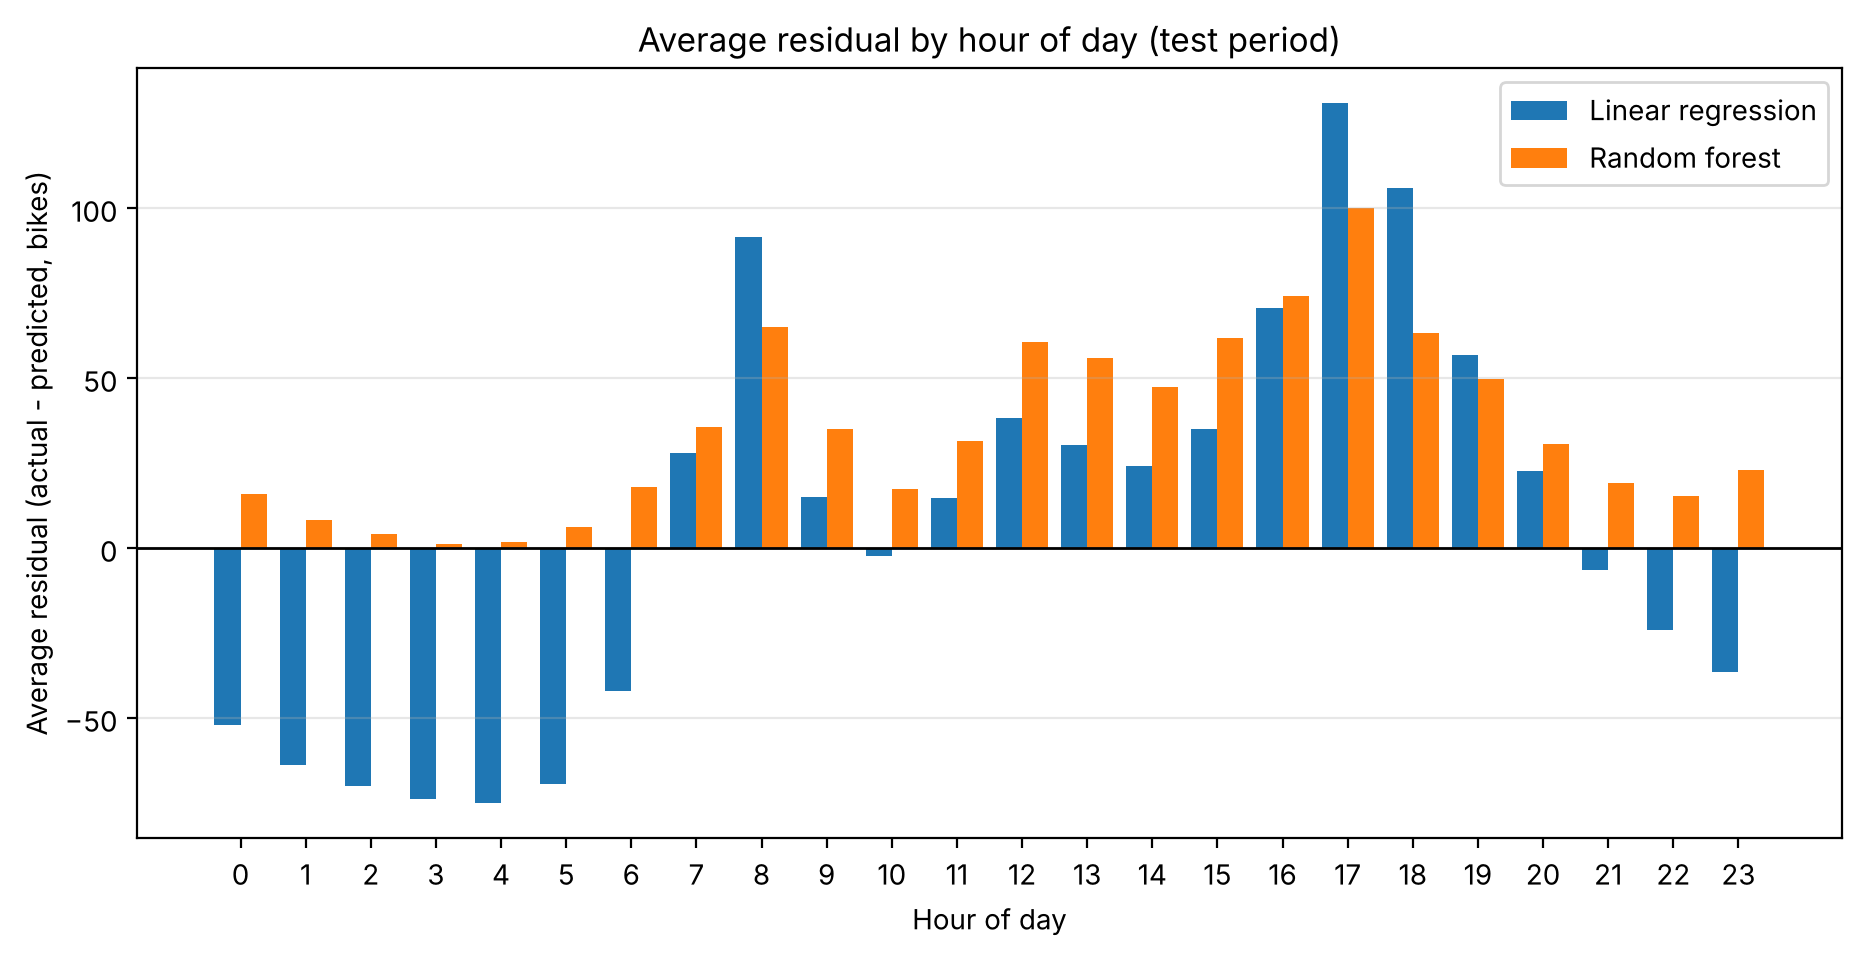

,y_true,linear,forest
hr,,,
3,14.8,88.7,13.6
8,489.4,397.9,424.3
17,617.0,486.1,516.8


In [3]:
preds['res_linear'] = preds['y_true'] - preds['linear']
preds['res_forest'] = preds['y_true'] - preds['forest']

by_hour = preds.groupby('hr')[['res_linear', 'res_forest']].mean()

x = np.arange(24)
w = 0.4
plt.figure(figsize=(11, 5))
plt.bar(x - w / 2, by_hour['res_linear'], width=w, label='Linear regression')
plt.bar(x + w / 2, by_hour['res_forest'], width=w, label='Random forest')
plt.axhline(0, color='black', linewidth=1)
plt.xticks(x)
plt.xlabel('Hour of day')
plt.ylabel('Average residual (actual - predicted, bikes)')
plt.title('Average residual by hour of day (test period)')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.savefig('../results/figures/residual_vs_hour.png', dpi=150, bbox_inches='tight')
plt.show()

# Average actual and predicted demand at three key hours
preds[preds['hr'].isin([3, 8, 17])].groupby('hr')[['y_true', 'linear', 'forest']].mean().round(1)

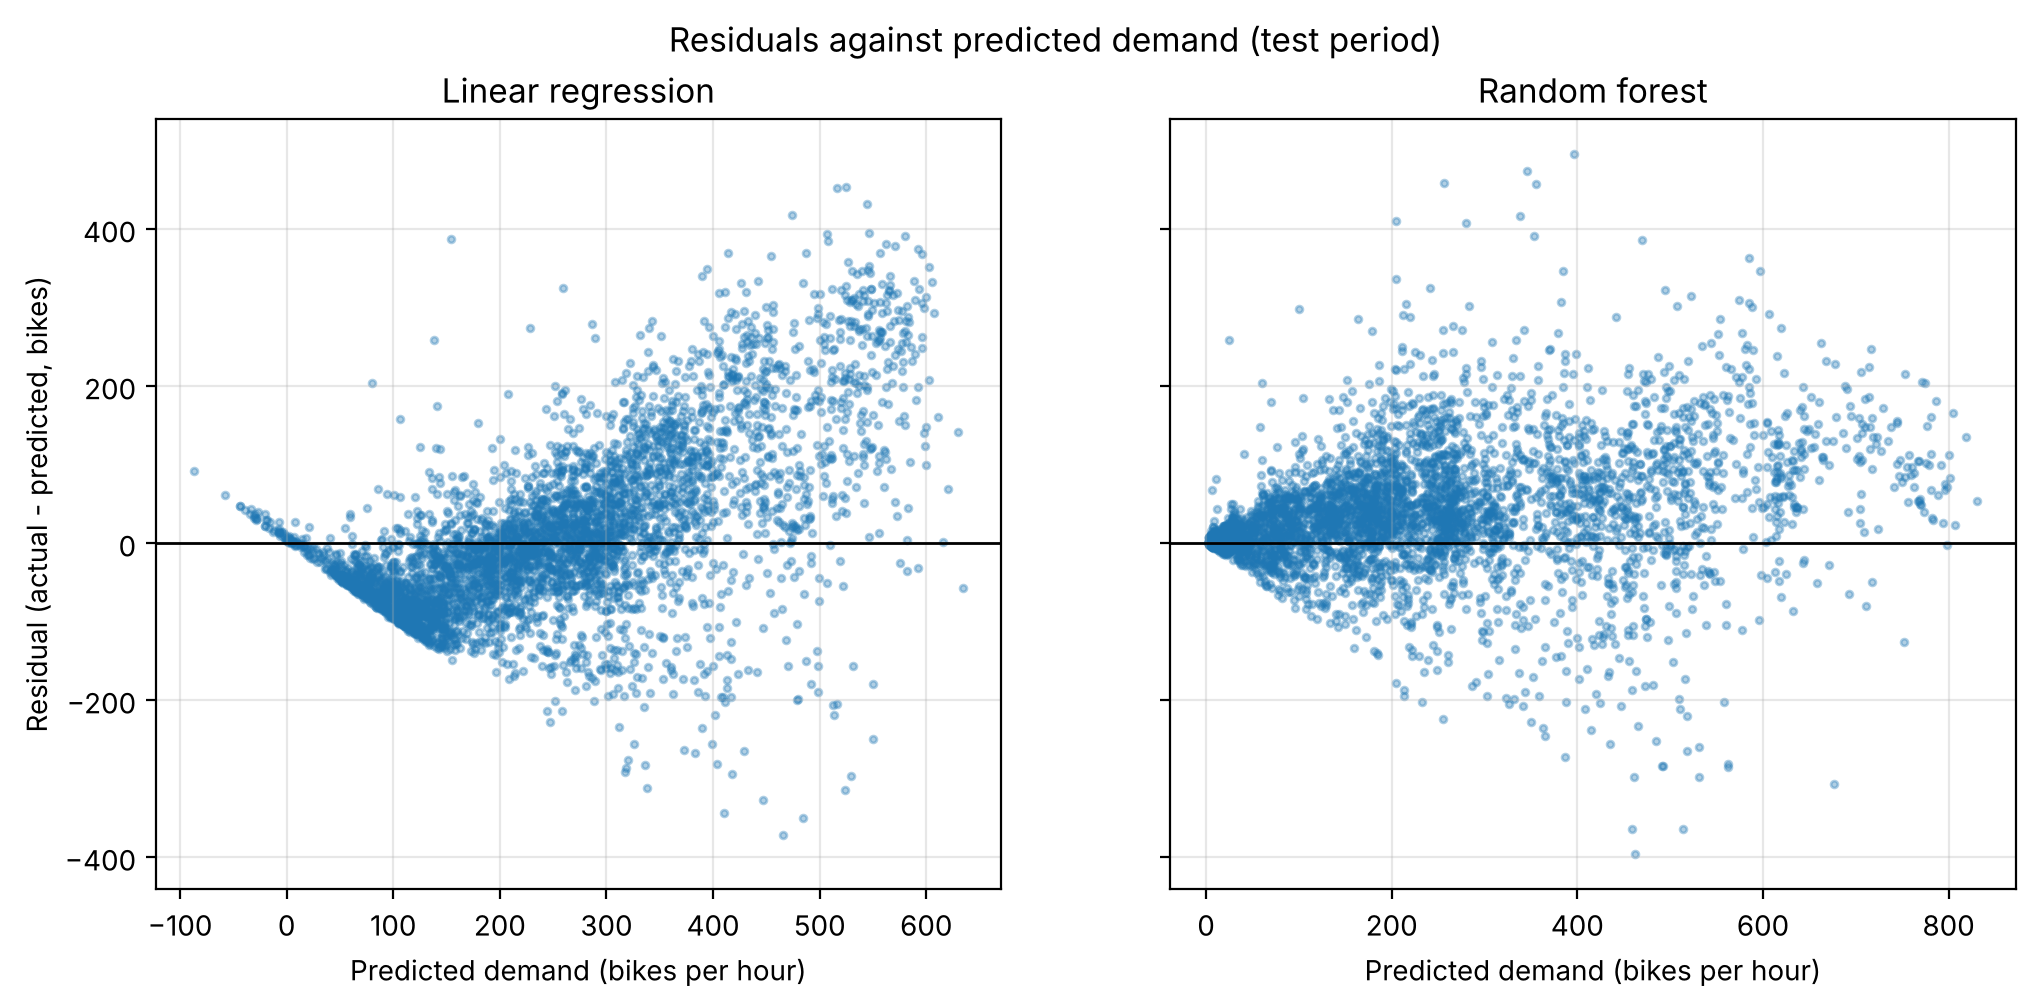

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, col, title in [(axes[0], 'linear', 'Linear regression'),
                       (axes[1], 'forest', 'Random forest')]:
    ax.scatter(preds[col], preds['y_true'] - preds[col], s=6, alpha=0.35)
    ax.axhline(0, color='black', linewidth=1)
    ax.set_title(title)
    ax.set_xlabel('Predicted demand (bikes per hour)')
    ax.grid(alpha=0.3)

axes[0].set_ylabel('Residual (actual - predicted, bikes)')
plt.suptitle('Residuals against predicted demand (test period)')
plt.savefig('../results/figures/residual_vs_predicted.png', dpi=150, bbox_inches='tight')
plt.show()

**Residuals against hour.** The linear model now follows the two commuter peaks, but it still under-predicts the rush hours and over-predicts the night. At 8 a.m. the real average demand in the test period is about 489 bikes and the linear model predicts about 398 (too low by about 92). At 5 p.m. the real value is about 617 and the prediction is about 486 (too low by about 131). At 3 a.m. it predicts about 89 bikes when the real value is about 15, and 37 of its predictions are negative, which is impossible. Its average residual ranges from about -75 to +131 bikes across the hours. The random forest follows the daily shape much better: it predicts about 14 bikes at 3 a.m. (real 15) and has no negative predictions. It still under-predicts on average at every hour (average residual between about 1 and 100 bikes), most at 5 p.m. (about 100) and at 8 a.m. (about 65). A likely reason, which we did not test, is the growth of the system: the training period only contains the first half of 2012 for `yr=1`, and a forest cannot extrapolate beyond the demand levels it has seen. For an operator, the 5 p.m. result means even the best model would plan for about 100 bikes fewer than people really rent at the busiest hour.

**Residuals against predicted demand.** If a model were right, the points would be spread evenly around zero. For both models the errors grow with the predicted level. For the linear model, the typical error (root mean square of the residuals) is about 55 bikes when the prediction is below 100, 73 for 100 to 300, 135 for 300 to 500 and 237 above 500. Its average residual is negative (-43) for low predictions and strongly positive (+200) for predictions above 500, so it over-predicts quiet hours and under-predicts busy ones. For the random forest the typical error is about 26 below 100, 82 for 100 to 300, 116 for 300 to 500 and 133 above 500, with an average residual of +86 above 500. So both under-predict high demand, the forest much less than the linear model.

## 4.3 Errors in peak hours

Peak hours are the hours where real demand is above the 90th percentile of the test period. These are the hours in which a fleet operator needs the forecast the most.

In [5]:
threshold = preds['y_true'].quantile(0.90)
peak = preds[preds['y_true'] > threshold]
print('Peak threshold: %.1f bikes per hour, peak hours: %d of %d' % (threshold, len(peak), len(preds)))

rows = []
for name in model_names:
    rows.append({
        'model': name,
        'overall RMSE': np.sqrt(mean_squared_error(preds['y_true'], preds[name])),
        'peak RMSE': np.sqrt(mean_squared_error(peak['y_true'], peak[name])),
        'average error at peaks (actual - predicted)': (peak['y_true'] - peak[name]).mean(),
    })

peak_table = pd.DataFrame(rows)
peak_table.round(1)

Peak threshold: 577.5 bikes per hour, peak hours: 438 of 4376


,model,overall RMSE,peak RMSE,average error at peaks (actual - predicted)
0,baseline,191.3,443.4,430.2
1,persistence,107.9,154.6,53.1
2,linear,107.1,238.1,225.6
3,ridge,107.1,238.2,225.6
4,lasso,107.1,238.1,225.6
5,forest,83.5,159.5,135.8


**What this shows.** Peak hours are the hardest hours for every model. The peak threshold is about 578 bikes per hour (438 hours). For the linear models the RMSE in peak hours is about 238, more than twice their overall RMSE of 107, and they are too low by about 226 bikes on average. For the random forest the peak RMSE is about 160 against an overall RMSE of 83, and it is too low by about 136 bikes on average. The persistence forecast is slightly better than the forest at peaks (peak RMSE about 155, and too low by only about 53 on average), because it copies last week's peaks while the forest smooths them. So even the best model misses the busiest hours the most, and an operator should plan a safety margin on top of the forecast at rush hour. Combining the forest with a persistence-type feature is a possible improvement.

## 4.4 RMSE or R²: which one to report to the operator

I would report **RMSE** (with MAE next to it) to the operator. RMSE is in bikes, so it directly says how far off a forecast can be: about 83 bikes per hour for the random forest. A truck planner can use that number. R² has no unit and depends on how spread out the demand in the test period is (the standard deviation of hourly demand here is about 220 bikes), so the same model can show a different R² in a quieter period or another city, and nobody can turn 0.856 into a number of bikes to move. RMSE also punishes big misses more than small ones, which fits fleet planning, because being 300 bikes short at a rush hour is much worse than being 30 bikes short several times. R² is still useful as a quick check of how much better a model is than always predicting the average.

## 4.5 Ridge coefficients

We refit the final Ridge model on the training period with the alpha chosen in `03-models.ipynb` (read from `results/best_params.csv`). The numeric features were standardised, so their coefficients mean bikes per hour for a change of one standard deviation. Season, weather, weekday and the 48 hour x working-day columns are 0 or 1, so their coefficients are bikes per hour compared with the other categories. The hour columns are shown separately as a daily profile.

Ridge alpha from best_params.csv: 0.001
Test RMSE of the refitted Ridge: 107.09


,coefficient
hour_daytype__hr_wd_3_1,-152.2
hour_daytype__hr_wd_4_1,-149.8
hour_daytype__hr_wd_2_1,-147.7
hour_daytype__hr_wd_5_0,-141.8
hour_daytype__hr_wd_1_1,-141.6
...,...
hour_daytype__hr_wd_12_0,147.3
hour_daytype__hr_wd_13_0,151.1
hour_daytype__hr_wd_18_1,253.2
hour_daytype__hr_wd_8_1,266.2


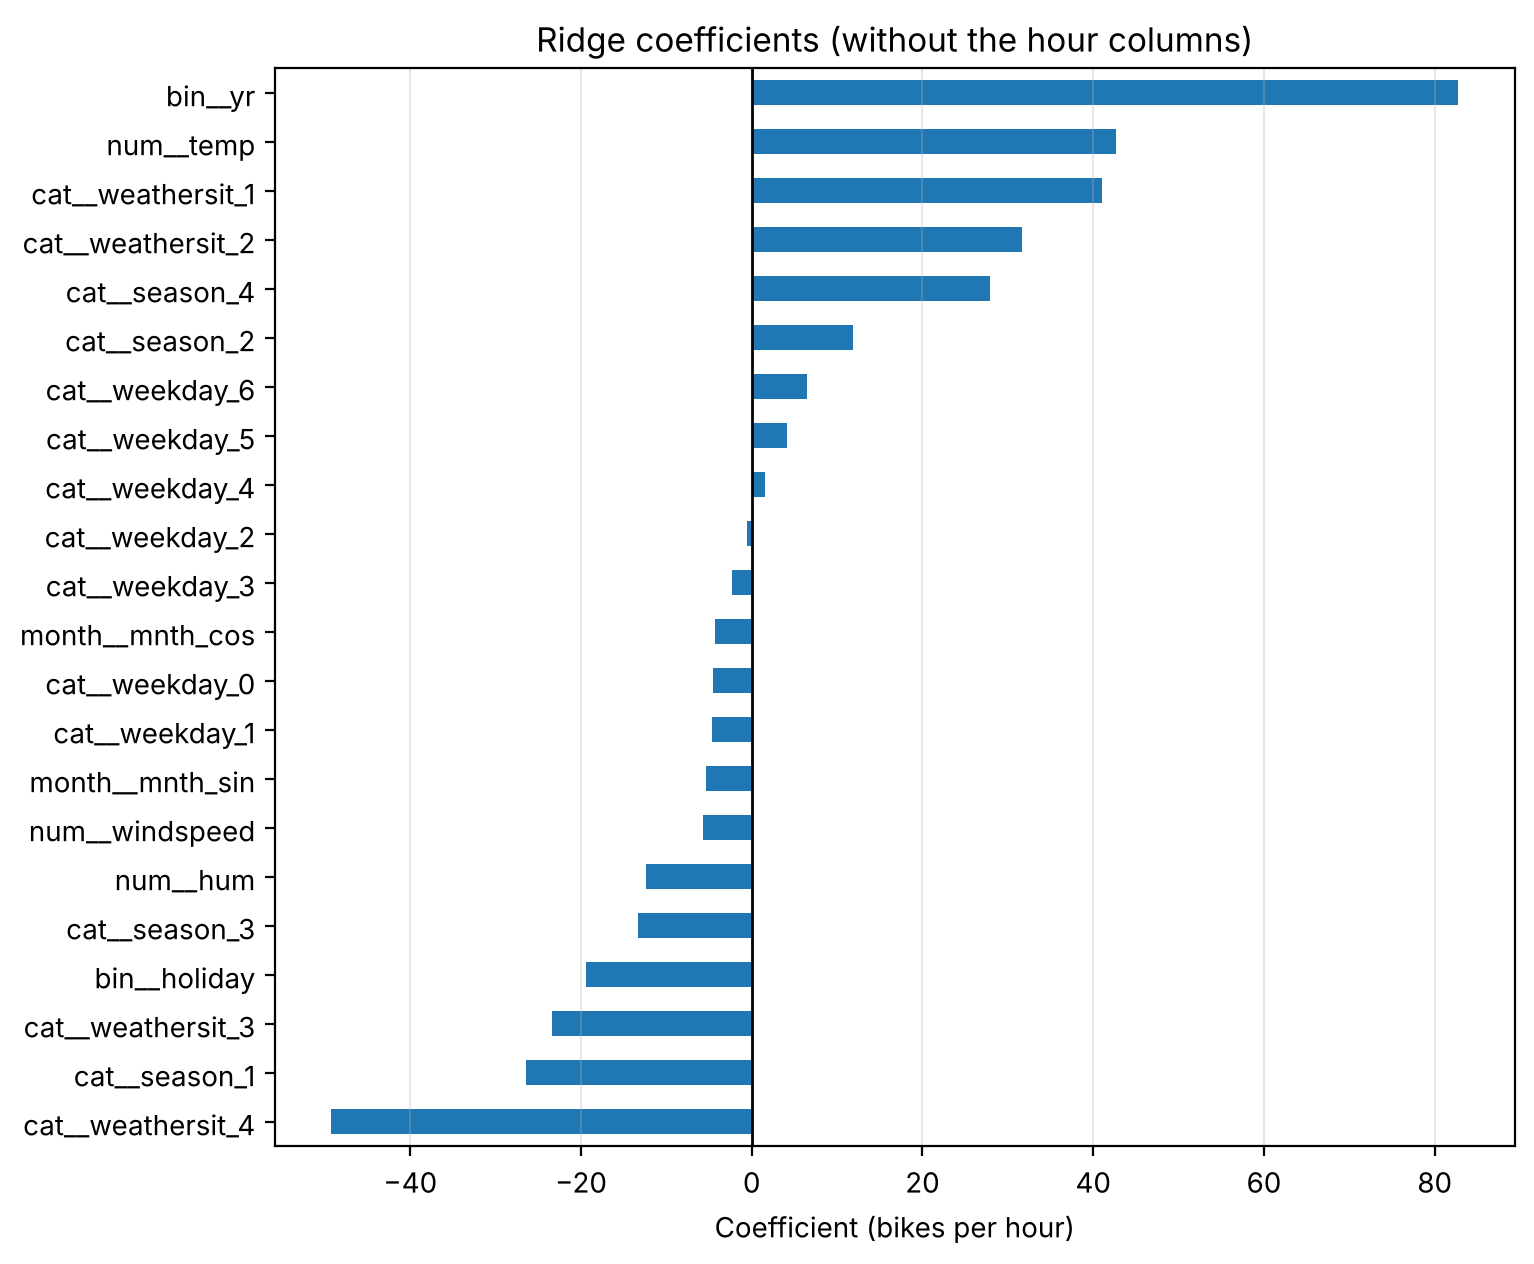

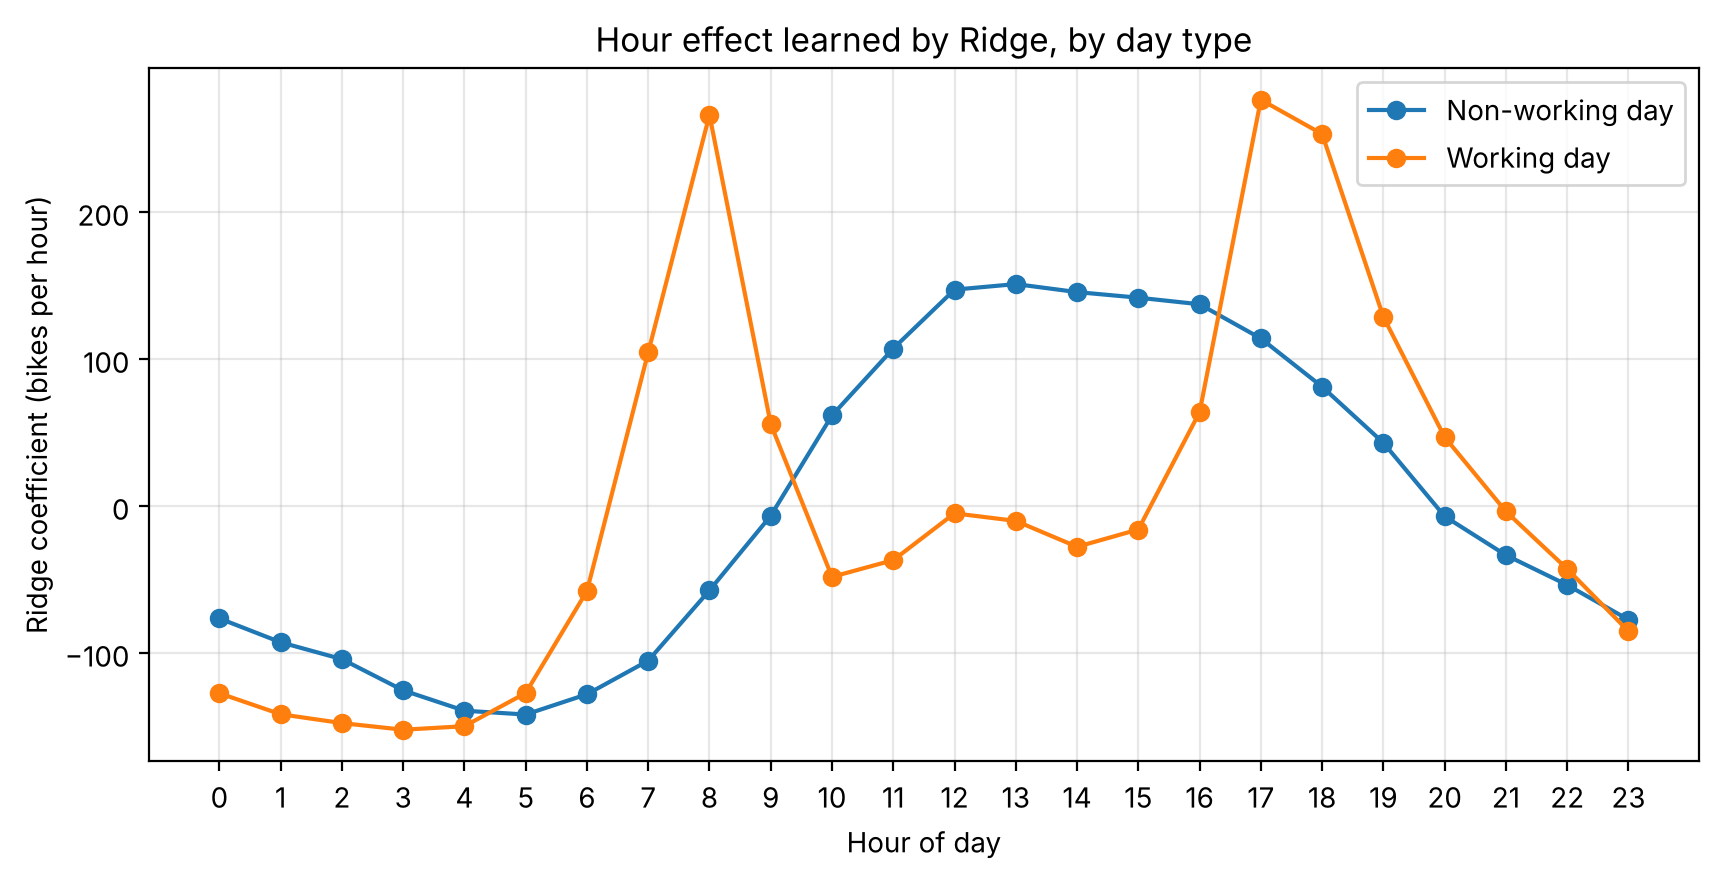

In [6]:
best = pd.read_csv('../results/best_params.csv', dtype=str)
ridge_alpha = float(best[(best['model'] == 'ridge') & (best['param'] == 'alpha')]['value'].iloc[0])
print('Ridge alpha from best_params.csv:', ridge_alpha)

df = load_hour_data()
train, test = chronological_split(df)
X_train, y_train = get_xy(train)
X_test, y_test = get_xy(test)

ridge_final = Pipeline([
    ('prep', build_preprocessor('linear')),
    ('model', Ridge(alpha=ridge_alpha)),
])
ridge_final.fit(X_train, y_train)

# Check: this should match the Ridge RMSE in the metrics table
check = np.sqrt(mean_squared_error(y_test, ridge_final.predict(X_test)))
print('Test RMSE of the refitted Ridge: %.2f' % check)

names = ridge_final.named_steps['prep'].get_feature_names_out()
coefs = pd.Series(ridge_final.named_steps['model'].coef_, index=names).sort_values()
display(coefs.round(1).to_frame('coefficient'))

# Hour effects (48 one-hot columns) are shown as a daily profile; all other coefficients as bars
is_hour = coefs.index.str.startswith('hour_daytype__')
other = coefs[~is_hour].sort_values()

plt.figure(figsize=(8, 7))
other.plot(kind='barh')
plt.axvline(0, color='black', linewidth=1)
plt.xlabel('Coefficient (bikes per hour)')
plt.title('Ridge coefficients (without the hour columns)')
plt.grid(axis='x', alpha=0.3)
plt.savefig('../results/figures/ridge_coefficients.png', dpi=150, bbox_inches='tight')
plt.show()

# Daily profile learned for working and non-working days (coefficient of each hour x day-type column)
hour_coefs = coefs[is_hour]
profile = pd.DataFrame({
    'Non-working day': [hour_coefs.get(f'hour_daytype__hr_wd_{h}_0', np.nan) for h in range(24)],
    'Working day': [hour_coefs.get(f'hour_daytype__hr_wd_{h}_1', np.nan) for h in range(24)],
}, index=range(24))
profile.plot(figsize=(10, 4.5), marker='o')
plt.xticks(range(24))
plt.xlabel('Hour of day')
plt.ylabel('Ridge coefficient (bikes per hour)')
plt.title('Hour effect learned by Ridge, by day type')
plt.grid(alpha=0.3)
plt.savefig('../results/figures/ridge_hour_profile.png', dpi=150, bbox_inches='tight')
plt.show()


**Hour profile (second figure).** The coefficients show a different daily shape for each day type. On working days the hour effect peaks at 8 a.m. (about +266) and at 5 and 6 p.m. (about +277 and +253). On non-working days there is no commuter peak, and the effect is highest around midday (about +147 at 12 and +151 at 1 p.m.). This is what the interaction columns were added for.

**Three other coefficients in plain words**

**1. Weather (`weathersit`).** Compared with clear weather (about +41), light rain or snow (level 3, about -23) lowers demand by about 64 bikes per hour, and mist (level 2, about +32) lowers it by about 9, when the hour, the day and the temperature are the same. For the operator: on a rainy day plan for far fewer rentals at the same hour, so fewer bikes have to be moved to busy stations. (The heavy rain level 4 has only 3 rows, all in the training period, so its coefficient is not reliable and we do not interpret it.)

**2. Year (`yr`).** The coefficient is about +83. For the same hour, weather and type of day, 2012 had about 83 more rentals per hour than 2011. This is the strong growth of the system, and it means last year's numbers are too low for this year. It is also a warning: the model only knows the values 0 (2011) and 1 (2012), so it cannot predict a new year like 2013 without new data.

**3. Temperature (`temp`).** `atemp` was dropped from the linear pipeline because it is almost the same measurement as `temp` (correlation 0.99), so `temp` now carries the whole temperature effect. Its coefficient is about +43 for a change of one standard deviation (about 9 degrees Celsius). So when it is about 9 degrees warmer, the model expects about 43 more rentals per hour. For the operator: warm days need more bikes in the field and cold days need fewer.

**Sign check: does bad weather reduce demand in our model?** Yes. The weather coefficients go down from clear (+41) to mist (+32) to light rain or snow (-23). Humidity (about -12 per standard deviation) and holidays (about -19) also lower demand, as expected.

## 4.6 Limitations

- The data is one city-wide hourly total. It has no station-level information, so it cannot say where to move bikes, only how many bikes will be rented overall.
- The models use the real weather of that hour. In real use the operator would only have a weather forecast, which is less accurate, so real errors would be larger.
- The year column cannot extrapolate to a new year, and the test period only covers July to December 2012. The forest under-predicts at every hour on average.
- 165 hours are missing from the data (0.94%), mostly quiet night hours and four long gaps. We kept them as missing and did not fill them.
- The linear models need the hour x working-day columns to show two daily peaks, and they are still only as accurate as the "same hour last week" forecast in RMSE. All models under-predict the busiest hours.

## 4.7 Check: which preprocessing for which model?

The linear models and the random forest use different preprocessing (`src/preprocessing.py`). This check fits both preprocessing variants with both model families on the training period and scores them on the test period, to show that each model family really is better off with its own variant.

In [7]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Full pipelines: the two preprocessing variants x the two model families.
# 'linear' = one-hot hour x working day (no atemp); 'forest' = cyclic hour.
rows = []
for kind in ['linear', 'forest']:
    for model_name, model in [
        ('linear regression', LinearRegression()),
        ('random forest (200 trees, defaults)', RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)),
    ]:
        pipe = Pipeline([('prep', build_preprocessor(kind)), ('model', model)])
        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_test)
        rows.append({
            'preprocessing': kind,
            'model': model_name,
            'RMSE': np.sqrt(mean_squared_error(y_test, pred)),
            'MAE': mean_absolute_error(y_test, pred),
            'R2': r2_score(y_test, pred),
        })

pd.DataFrame(rows).round(3)

,preprocessing,model,RMSE,MAE,R2
0,linear,linear regression,107.090,80.200,0.762
1,linear,"random forest (200 trees, defaults)",92.272,64.330,0.824
2,forest,linear regression,165.733,123.920,0.431
3,forest,"random forest (200 trees, defaults)",83.531,56.308,0.855


**Decision.** Each model family is better off with its own preprocessing. Linear regression: one-hot hour x working day gives RMSE 107.1, the cyclic-hour version gives 165.7. Random forest: the cyclic-hour version gives RMSE 83.5 (R² 0.855) and the one-hot version 92.3 (R² 0.824). A likely reason is that a tree can group neighbouring hours with one split when it has the sine and cosine pair, while 48 separate yes/no columns make each split look at only one hour and day type, and trees find the hour x working-day interaction without help. So `src/preprocessing.py` keeps two variants: `'linear'` and `'forest'`. The random forest remains the best model by a clear margin.

## Summary

- Best model: random forest, RMSE about 83 bikes per hour, MAE about 56, R² about 0.856 on July to December 2012.
- Linear regression, Ridge and Lasso are almost identical (RMSE about 107, R² 0.762); regularisation did not help.
- With one-hot hour x working day, the linear models improved from RMSE 165.7 to 107.1, but they only match the "same hour last week" forecast (RMSE 107.9) and are worse in MAE (80.2 versus 63.1). Only the random forest clearly beats it.
- All models make their biggest errors in the busiest hours and under-predict them; the forest is too low by about 136 bikes on average in the peak hours.
- Coefficients behave as expected: bad weather lowers demand, warm weather raises it, and 2012 had much more demand than 2011.
- Headline metric for the operator: RMSE, because it is in bikes.